# DX799 Week 5: Support Vector Machines, Kernels, and Regularization

## 1. Definitions and modeling safeguards

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
SEED=42
path=Path('movies.csv')
if not path.exists():path=Path('/mnt/data/movies.csv')
raw=pd.read_csv(path)
print('Original dataset:',raw.shape,'| source:',path)

Original dataset: (18905, 23) | source: movies.csv


## 2. Reproduce the Week 4 classification sample

In [2]:
df=raw.drop_duplicates(subset=['movie_id']).copy()
df['release_date']=pd.to_datetime(df['release_date'],errors='coerce')
df['release_year']=pd.to_numeric(df['release_year'],errors='coerce')
for name in ['budget','revenue','runtime']: df[name]=pd.to_numeric(df[name],errors='coerce')
df=df.loc[(df.budget>0)&(df.revenue>0)&df.release_year.between(1980,2024)&df.runtime.between(40,240)&df.release_date.notna()].copy()
df['budget_m']=df.budget/1e6
df['gross_to_budget']=df.revenue/df.budget
df['success']=(df.gross_to_budget>=2).astype(int)
parsed_genres=df.genres.fillna('').str.split('|')
df['animation']=parsed_genres.map(lambda g:int('Animation' in g))
df['release_month']=df.release_date.dt.month
for genre in ['Action','Comedy','Drama','Horror']:
    df['genre_'+genre.lower()]=parsed_genres.map(lambda g:int(genre in g))
for month in range(2,13):df[f'month_{month}']=(df.release_month==month).astype(int)
features=['budget_m','runtime','release_year','animation','genre_action','genre_comedy','genre_drama','genre_horror']+[f'month_{i}' for i in range(2,13)]
tr,te=train_test_split(np.arange(len(df)),test_size=.2,random_state=SEED)
train,test=df.iloc[tr].copy(),df.iloc[te].copy()
X_train,X_test=train[features],test[features]
y_train,y_test=train.success,test.success
print(f'Filtered: {len(df):,} | train: {len(train):,} | test: {len(test):,} | features: {len(features)}')
print(f'Success overall: {df.success.mean():.1%}; train: {y_train.mean():.1%}; test: {y_test.mean():.1%}')
print('Animation movies:',int(df.animation.sum()))

Filtered: 7,079 | train: 5,663 | test: 1,416 | features: 19
Success overall: 43.6%; train: 43.7%; test: 43.1%
Animation movies: 376


## 3. Exploratory analysis: predictor differences across classes

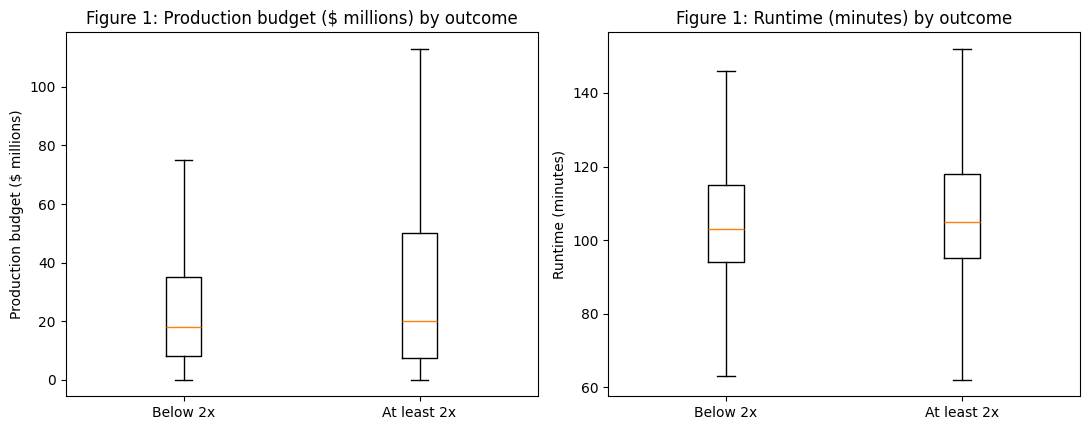

In [3]:
fig,axs=plt.subplots(1,2,figsize=(11,4.4))
for ax,col,label in zip(axs,['budget_m','runtime'],['Production budget ($ millions)','Runtime (minutes)']):
    vals=[df.loc[df.success==j,col] for j in [0,1]]
    ax.boxplot(vals,showfliers=False)
    ax.set_xticks([1,2],['Below 2x','At least 2x'])
    ax.set(ylabel=label,title=f'Figure 1: {label} by outcome')
plt.tight_layout();plt.show()

## 4. Cross-validation: tune SVM kernels and hyperparameters

In [4]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
configurations={
 'Linear SVM': ('linear', {'svc__C':[.01,.1,1,10]}),
 'Polynomial SVM': ('poly', {'svc__C':[.1,1,10],'svc__gamma':['scale',.01]}),
 'RBF SVM': ('rbf', {'svc__C':[.1,1,10],'svc__gamma':['scale',.01]})
}
tuned={}; searches={}
for name,(kernel,grid) in configurations.items():
    pipe=Pipeline([('scale',StandardScaler()),('svc',SVC(kernel=kernel,degree=2,coef0=1,cache_size=500))])
    search=GridSearchCV(pipe,grid,scoring='roc_auc',cv=cv,n_jobs=-1,pre_dispatch='2*n_jobs',return_train_score=True)
    search.fit(X_train,y_train)
    searches[name]=search; tuned[name]=search.best_estimator_
    print(f'{name}: best params = {search.best_params_}; mean training-fold ROC-AUC = {search.best_score_:.4f}')

Linear SVM: best params = {'svc__C': 0.1}; mean training-fold ROC-AUC = 0.5863


Polynomial SVM: best params = {'svc__C': 10, 'svc__gamma': 'scale'}; mean training-fold ROC-AUC = 0.6061


RBF SVM: best params = {'svc__C': 10, 'svc__gamma': 'scale'}; mean training-fold ROC-AUC = 0.6174


## 5. Visualize regularization, kernel flexibility, and validation gaps

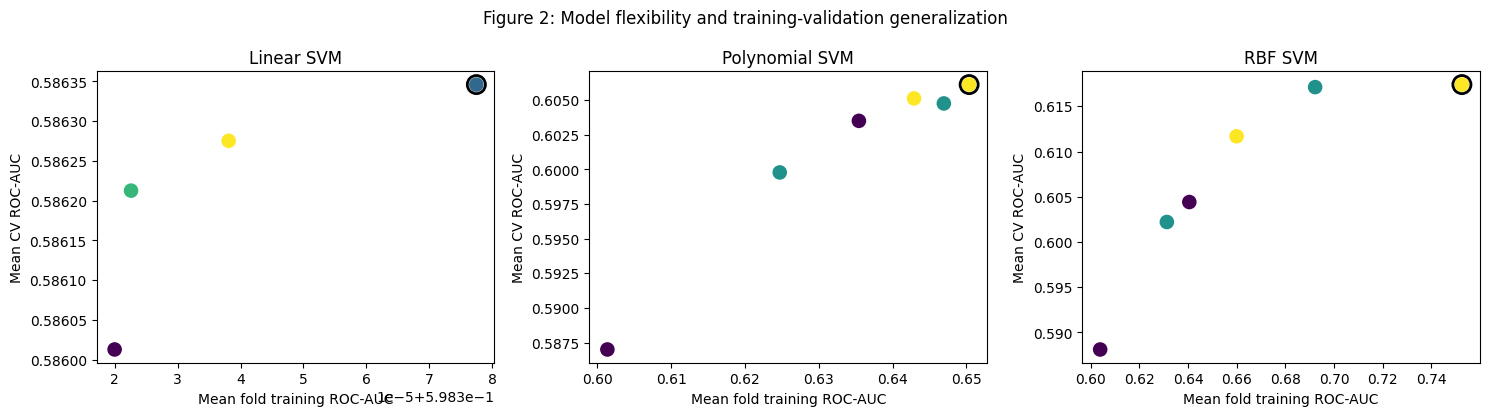

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4.2))
for ax,(name,search) in zip(axes,searches.items()):
    z=pd.DataFrame(search.cv_results_)
    ax.scatter(z.mean_train_score,z.mean_test_score,c=np.log10(z['param_svc__C'].astype(float)),cmap='viridis',s=90)
    j=search.best_index_
    ax.scatter([z.loc[j,'mean_train_score']],[z.loc[j,'mean_test_score']],s=170,facecolors='none',edgecolors='black',linewidths=2)
    ax.set(title=name,xlabel='Mean fold training ROC-AUC',ylabel='Mean CV ROC-AUC')
plt.suptitle('Figure 2: Model flexibility and training-validation generalization')
plt.tight_layout();plt.show()

## 6. Holdout evaluation with Week 4 logistic comparison

In [6]:
log_search=GridSearchCV(Pipeline([('scale',StandardScaler()),('clf',LogisticRegression(max_iter=6000,solver='liblinear',random_state=SEED))]),
                        {'clf__C':[.001,.01,.1,1,10,100]},scoring='roc_auc',cv=cv,n_jobs=-1)
log_search.fit(X_train,y_train)
log_model=log_search.best_estimator_
print('Logistic baseline: C =',log_search.best_params_['clf__C'],'CV ROC-AUC =',round(log_search.best_score_,4))
def assess(name,model,is_svm=True):
    scores=model.decision_function(X_test) if is_svm else model.predict_proba(X_test)[:,1]
    pred=model.predict(X_test)
    tr_scores=model.decision_function(X_train) if is_svm else model.predict_proba(X_train)[:,1]
    return {'Model':name,'Train ROC-AUC':roc_auc_score(y_train,tr_scores),
            'Test ROC-AUC':roc_auc_score(y_test,scores),
            'Average precision':average_precision_score(y_test,scores),
            'Accuracy':accuracy_score(y_test,pred),'Balanced accuracy':balanced_accuracy_score(y_test,pred),
            'Precision':precision_score(y_test,pred,zero_division=0),
            'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0)}
results=pd.DataFrame([assess('Scaled Logistic',log_model,False)]+[assess(name,m) for name,m in tuned.items()]).set_index('Model')
print(results.round(4).to_string())
print('Largest held-out ROC-AUC:',results['Test ROC-AUC'].idxmax())

Logistic baseline: C = 0.01 CV ROC-AUC = 0.6089


                 Train ROC-AUC  Test ROC-AUC  Average precision  Accuracy  Balanced accuracy  Precision  Recall      F1
Model                                                                                                                  
Scaled Logistic         0.6194        0.6137             0.5376    0.5911             0.5595     0.5432  0.3290  0.4098
Linear SVM              0.5972        0.5916             0.5117    0.5777             0.5329     0.5272  0.2062  0.2965
Polynomial SVM          0.6451        0.6183             0.5516    0.6073             0.5701     0.5890  0.2979  0.3957
RBF SVM                 0.7415        0.6092             0.5474    0.6003             0.5717     0.5564  0.3633  0.4396
Largest held-out ROC-AUC: Polynomial SVM


## 7. ROC and precision-recall curves

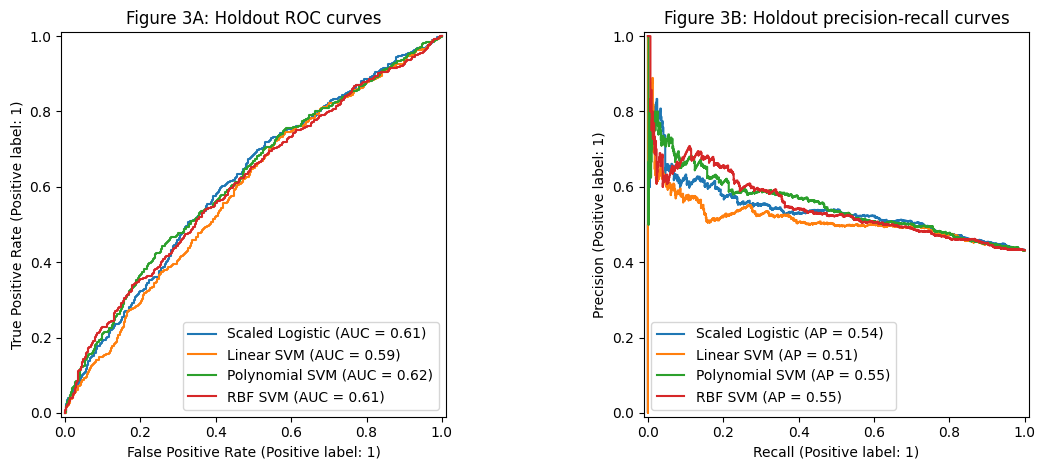

In [7]:
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for name,model in [('Scaled Logistic',log_model)]+list(tuned.items()):
    RocCurveDisplay.from_estimator(model,X_test,y_test,ax=axs[0],name=name)
    PrecisionRecallDisplay.from_estimator(model,X_test,y_test,ax=axs[1],name=name)
axs[0].set_title('Figure 3A: Holdout ROC curves')
axs[1].set_title('Figure 3B: Holdout precision-recall curves')
plt.tight_layout();plt.show()

## 8. Confusion matrix and support vectors

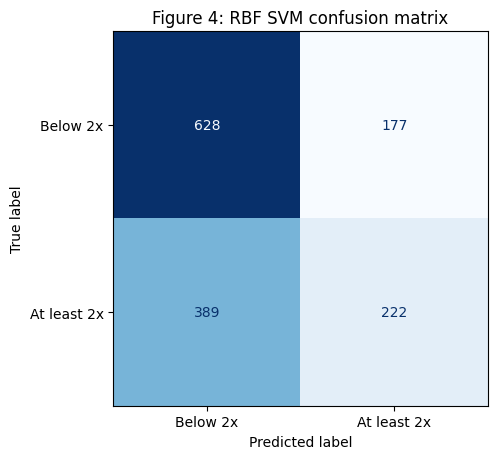

Best by training CV: RBF SVM
Linear SVM: support vectors = 4,818 of 5,663 (85.1%); class counts=[2412 2406]
Polynomial SVM: support vectors = 4,558 of 5,663 (80.5%); class counts=[2298 2260]
RBF SVM: support vectors = 4,451 of 5,663 (78.6%); class counts=[2271 2180]


In [8]:
best_name=max(searches,key=lambda name:searches[name].best_score_)
best_model=tuned[best_name]
cm=confusion_matrix(y_test,best_model.predict(X_test),labels=[0,1])
fig,ax=plt.subplots(figsize=(5.8,4.7))
ConfusionMatrixDisplay(cm,display_labels=['Below 2x','At least 2x']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title(f'Figure 4: {best_name} confusion matrix')
plt.tight_layout();plt.show()
print('Best by training CV:',best_name)
for name,model in tuned.items():
    svc=model.named_steps['svc']
    print(f'{name}: support vectors = {len(svc.support_):,} of {len(X_train):,} ({len(svc.support_)/len(X_train):.1%}); class counts={svc.n_support_}')

## 9. Coefficient interpretation and limitations

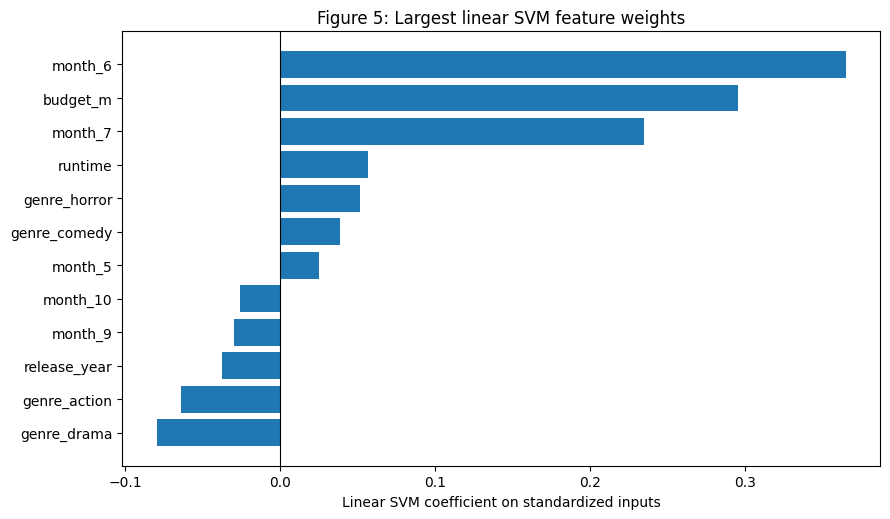

genre_drama    -0.080
genre_action   -0.064
release_year   -0.038
month_9        -0.030
month_10       -0.026
month_5         0.025
genre_comedy    0.039
genre_horror    0.052
runtime         0.056
month_7         0.234
budget_m        0.295
month_6         0.365


In [9]:
coef=pd.Series(tuned['Linear SVM'].named_steps['svc'].coef_[0],index=features)
top=coef.reindex(coef.abs().sort_values(ascending=False).head(12).index).sort_values()
fig,ax=plt.subplots(figsize=(9,5.3))
ax.barh(top.index,top.values)
ax.axvline(0,color='black',linewidth=.8)
ax.set(xlabel='Linear SVM coefficient on standardized inputs',title='Figure 5: Largest linear SVM feature weights')
plt.tight_layout();plt.show()
print(top.round(3).to_string())

## 10. Interpretation and conclusions for Milestone One

In [10]:
print('DATA:',f'{len(df):,} movies, {len(features)} predictors, success fraction {df.success.mean():.1%}')
for name,r in results.iterrows():
    print(f'{name}: test ROC-AUC={r["Test ROC-AUC"]:.4f}, F1={r["F1"]:.4f}, accuracy={r["Accuracy"]:.4f}, recall={r["Recall"]:.4f}, train-test ROC-AUC gap={r["Train ROC-AUC"]-r["Test ROC-AUC"]:+.4f}')
print('Recommended SVM by training CV:',best_name,'| kernel:',best_model.named_steps['svc'].kernel)
print('Test ROC-AUC difference vs scaled logistic:',round(results.loc[best_name,'Test ROC-AUC']-results.loc['Scaled Logistic','Test ROC-AUC'],4))
print('Reminder: these scores classify gross-to-budget outcomes. They are not comparable to revenue regression R-squared.')

DATA: 7,079 movies, 19 predictors, success fraction 43.6%
Scaled Logistic: test ROC-AUC=0.6137, F1=0.4098, accuracy=0.5911, recall=0.3290, train-test ROC-AUC gap=+0.0057
Linear SVM: test ROC-AUC=0.5916, F1=0.2965, accuracy=0.5777, recall=0.2062, train-test ROC-AUC gap=+0.0056
Polynomial SVM: test ROC-AUC=0.6183, F1=0.3957, accuracy=0.6073, recall=0.2979, train-test ROC-AUC gap=+0.0268
RBF SVM: test ROC-AUC=0.6092, F1=0.4396, accuracy=0.6003, recall=0.3633, train-test ROC-AUC gap=+0.1324
Recommended SVM by training CV: RBF SVM | kernel: rbf
Test ROC-AUC difference vs scaled logistic: -0.0045
Reminder: these scores classify gross-to-budget outcomes. They are not comparable to revenue regression R-squared.
